<div style="
    background-color:#f0f6ff;
    border-left:6px solid #1f77b4;
    padding:18px 22px;
    border-radius:8px;
    font-family: 'Segoe UI', Arial, sans-serif;
">

<h2 style="margin-top:0; color:#1f3b5f;">
📊 Problema 1. Fluctuaciones a corto plazo
</h2>

<p style="font-size:15px; line-height:1.6; color:#2c3e50;">
El objetivo de este ejercicio es analizar parte de la evidencia empírica relacionada con
las <strong>fluctuaciones a corto plazo</strong> de la economía española y su relación con la
economía de <strong>Estados Unidos</strong>.
</p>

<p style="font-size:15px; line-height:1.6; color:#2c3e50;">
Para ello, el estudiante deberá <strong>descargar y trabajar con distintas series temporales</strong>
que permitan caracterizar el comportamiento cíclico de ambas economías y, a partir de
ellas, <strong>responder a las preguntas planteadas</strong> en el ejercicio.
</p>

</div>


> ### Parte 1 — Ciclo como desviación del crecimiento respecto a una tendencia constante
> 
> **Supuesto:** el crecimiento tendencial es constante.  
> Bajo este supuesto, el ciclo se define como:
> 
> $$
> c_t = g_t - \bar g
> $$
> 
> donde $g_t$ es el crecimiento observado, $\bar g$ el crecimiento tendencial (constante) y $c_t$ el componente cíclico.





In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Cargar datos desde Excel
file_path = "data_ej1.xlsx"

df_esp = pd.read_excel(file_path, sheet_name="ESP")
df_usa = pd.read_excel(file_path, sheet_name="EEUU")

# Asegurar formato fecha
df_esp["date"] = pd.to_datetime(df_esp["date"])
df_usa["date"] = pd.to_datetime(df_usa["date"])

df_esp.set_index("date", inplace=True)
df_usa.set_index("date", inplace=True)


In [31]:
import numpy as np

# Seleccionar PIB real
gdp_esp = df_esp["PIB_real"]
gdp_usa = df_usa["GDP_real"]

# Tasa de crecimiento: log-diferencias (en %)
g_esp = 100 * np.log(gdp_esp).diff()
g_usa = 100 * np.log(gdp_usa).diff()

# Crecimiento tendencial constante (media muestral)
gbar_esp = g_esp.mean()
gbar_usa = g_usa.mean()

# Ciclo
cycle_esp = g_esp - gbar_esp
cycle_usa = g_usa - gbar_usa


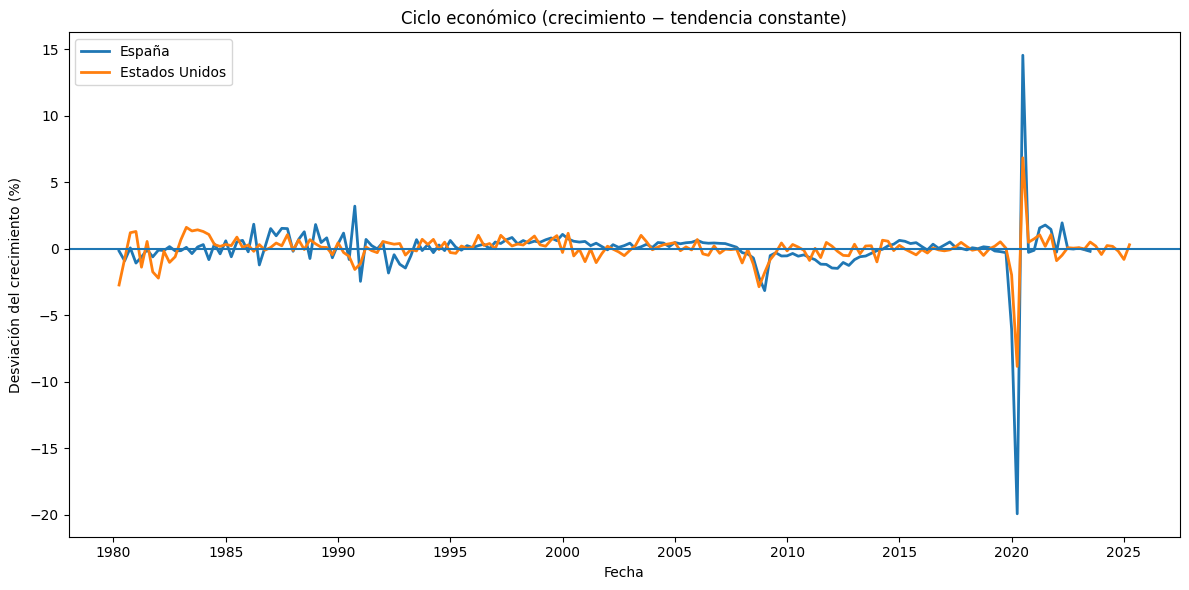

In [32]:
plt.figure(figsize=(12,6))

plt.plot(cycle_esp, label="España", linewidth=2)
plt.plot(cycle_usa, label="Estados Unidos", linewidth=2)

plt.axhline(0)
plt.title("Ciclo económico (crecimiento − tendencia constante)")
plt.ylabel("Desviación del crecimiento (%)")
plt.xlabel("Fecha")
plt.legend()
plt.tight_layout()
plt.show()


<div style="background-color:#e6ffe6; padding:15px; border-radius:10px; border:1px solid #b3ffb3;">

El gráfico muestra cómo se comporta el ciclo económico de España y Estados Unidos cuando se mide como la desviación del crecimiento respecto a una tendencia constante. En la mayor parte del período, ambos países presentan fluctuaciones relativamente moderadas alrededor de cero, lo que indica que el crecimiento suele moverse cerca de su nivel tendencial.

Se observa que los ciclos de ambos países están bastante sincronizados en los grandes episodios económicos. Destaca claramente la crisis financiera de 2008–2009, donde el crecimiento cae por debajo de la tendencia en ambos casos, y de forma mucho más intensa la crisis de 2020, asociada a la pandemia, que provoca una caída muy fuerte, especialmente en España.

En general, el ciclo español muestra mayor volatilidad que el estadounidense, con oscilaciones más pronunciadas tanto en las fases expansivas como en las recesivas. Estados Unidos presenta un comportamiento más estable, con fluctuaciones de menor amplitud. Esto sugiere que la economía española es más sensible a los shocks económicos que la estadounidense.

</div>




> ## Parte 2 — Comparación con filtro Hodrick-Prescott (HP) y volatilidad
> 
> Ahora comparamos el ciclo obtenido como (crecimiento observado − crecimiento medio) con el ciclo obtenido aplicando el filtro HP a los logaritmos de los niveles.
> 
> - HP sobre datos anuales: λ = 100  
> - HP sobre datos trimestrales: λ = 1600  
> 
> Para cada serie calculamos:  
> 1) Volatilidad del ciclo (desviación típica)  
> 2) Volatilidad relativa respecto a la del PIB (vol(ciclo_serie) / vol(ciclo_PIB))


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.filters.hp_filter import hpfilter

file_path = "data_ej1.xlsx"
df_esp = pd.read_excel(file_path, sheet_name="ESP")
df_usa = pd.read_excel(file_path, sheet_name="EEUU")

# Ajusta aquí si tu columna de fechas se llama distinto
date_col = "date"  # cambia si hace falta

df_esp[date_col] = pd.to_datetime(df_esp[date_col])
df_usa[date_col] = pd.to_datetime(df_usa[date_col])

df_esp = df_esp.set_index(date_col).sort_index()
df_usa = df_usa.set_index(date_col).sort_index()

def detect_lambda(idx):
    # Si es trimestral -> 1600, si es anual -> 100
    # (lo detectamos por distancia mediana entre fechas)
    diffs = idx.to_series().diff().dropna()
    median_days = diffs.dt.days.median()
    if median_days is not None and median_days < 200:
        return 1600, "trimestral"
    else:
        return 100, "anual"

lam_esp, freq_esp = detect_lambda(df_esp.index)
lam_usa, freq_usa = detect_lambda(df_usa.index)

lam_esp, freq_esp, lam_usa, freq_usa


(1600, 'trimestral', 1600, 'trimestral')

In [34]:
def cycle_growth_constant(x):
    # ciclo = 100*Δlog(x) - media(100*Δlog(x))
    g = 100 * np.log(x).diff()
    return g - g.mean()

def cycle_hp_log(x, lam):
    # HP sobre log-niveles: ciclo = log(x) - tendencia_HP(log(x))
    lx = np.log(x).dropna()
    cycle, trend = hpfilter(lx, lamb=lam)
    return cycle

def cycle_hp_level(x, lam):
    # HP sobre niveles (para tasas/porcentajes como paro)
    x2 = x.dropna()
    cycle, trend = hpfilter(x2, lamb=lam)
    return cycle

def build_cycles(df, lam, gdp_col, log_vars, level_vars):
    cycles = {}
    # ciclos por crecimiento (solo para log_vars)
    for c in log_vars:
        if c in df.columns:
            s = pd.to_numeric(df[c], errors="coerce")
            cycles[(c, "growth_const")] = cycle_growth_constant(s)
            cycles[(c, "hp_log")] = cycle_hp_log(s, lam)

    # variables en nivel (por ejemplo paro)
    for c in level_vars:
        if c in df.columns:
            s = pd.to_numeric(df[c], errors="coerce")
            cycles[(c, "hp_level")] = cycle_hp_level(s, lam)

    # PIB: lo usamos como referencia de volatilidad
    gdp_series_growth = cycles.get((gdp_col, "growth_const"))
    gdp_series_hp = cycles.get((gdp_col, "hp_log"))
    return cycles, gdp_series_growth, gdp_series_hp

# ---- AJUSTA ESTOS NOMBRES A TUS COLUMNAS ----
# Pon aquí el nombre exacto del PIB real en cada hoja:
gdp_esp_col = "PIB_real"
gdp_usa_col = "GDP_real"

# Variables que están en niveles positivos y tiene sentido tomar log
log_vars_esp = [gdp_esp_col, "Consumo", "Gasto_publico", "Inversion", "Horas"]  # ajusta si difieren
log_vars_usa = [gdp_usa_col, "PCE_real", "Gov_exp", "Inv_real", "Hours"]       # ajusta si difieren

# Variables que NO conviene logaritmar (porcentaje / tasa)
level_vars_esp = ["Paro"]   # ajusta si difiere
level_vars_usa = ["Unemployment_rate"]  # ajusta si difiere

cycles_esp, gdp_cyc_g_esp, gdp_cyc_hp_esp = build_cycles(df_esp, lam_esp, gdp_esp_col, log_vars_esp, level_vars_esp)
cycles_usa, gdp_cyc_g_usa, gdp_cyc_hp_usa = build_cycles(df_usa, lam_usa, gdp_usa_col, log_vars_usa, level_vars_usa)

len(cycles_esp), len(cycles_usa)


c:\Users\Usuario\GitHub\ucm\venv_ucm\Lib\site-packages\statsmodels\tsa\filters\hp_filter.py:100: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  trend = spsolve(I+lamb*K.T.dot(K), x, use_umfpack=use_umfpack)


(11, 11)

In [35]:
def volatility_table(cycles, gdp_col, gdp_cyc_growth, gdp_cyc_hp):
    rows = []
    # volatilidad PIB (referencia)
    vol_gdp_growth = gdp_cyc_growth.std(skipna=True) if gdp_cyc_growth is not None else np.nan
    vol_gdp_hp = gdp_cyc_hp.std(skipna=True) if gdp_cyc_hp is not None else np.nan

    for (var, method), cyc in cycles.items():
        vol = cyc.std(skipna=True)
        if method == "growth_const":
            rel = vol / vol_gdp_growth if vol_gdp_growth and not np.isnan(vol_gdp_growth) else np.nan
            rows.append([var, method, vol, rel])
        elif method == "hp_log" and var == gdp_col:
            rel = vol / vol_gdp_hp if vol_gdp_hp and not np.isnan(vol_gdp_hp) else np.nan
            rows.append([var, method, vol, rel])
        elif method == "hp_log":
            rel = vol / vol_gdp_hp if vol_gdp_hp and not np.isnan(vol_gdp_hp) else np.nan
            rows.append([var, method, vol, rel])
        elif method == "hp_level":
            # Relativo a PIB HP (comparación típica)
            rel = vol / vol_gdp_hp if vol_gdp_hp and not np.isnan(vol_gdp_hp) else np.nan
            rows.append([var, method, vol, rel])

    out = pd.DataFrame(rows, columns=["serie", "metodo", "volatilidad", "vol_relativa_a_PIB"])
    return out.sort_values(["metodo", "serie"]).reset_index(drop=True)

tab_esp = volatility_table(cycles_esp, gdp_esp_col, gdp_cyc_g_esp, gdp_cyc_hp_esp)
tab_usa = volatility_table(cycles_usa, gdp_usa_col, gdp_cyc_g_usa, gdp_cyc_hp_usa)

tab_esp, tab_usa


(            serie        metodo  volatilidad  vol_relativa_a_PIB
 0         Consumo  growth_const     2.574202            1.235327
 1   Gasto_publico  growth_const     1.061224            0.509268
 2           Horas  growth_const     3.025472            1.451886
 3       Inversion  growth_const     3.045809            1.461645
 4        PIB_real  growth_const     2.083822            1.000000
 5            Paro      hp_level     1.212810           52.481933
 6         Consumo        hp_log     0.026111            1.129921
 7   Gasto_publico        hp_log     0.013588            0.587985
 8           Horas        hp_log     0.028669            1.240586
 9       Inversion        hp_log     0.043730            1.892344
 10       PIB_real        hp_log     0.023109            1.000000,
                 serie        metodo  volatilidad  vol_relativa_a_PIB
 0            GDP_real  growth_const     1.082267            1.000000
 1             Gov_exp  growth_const     3.997988            3.6940

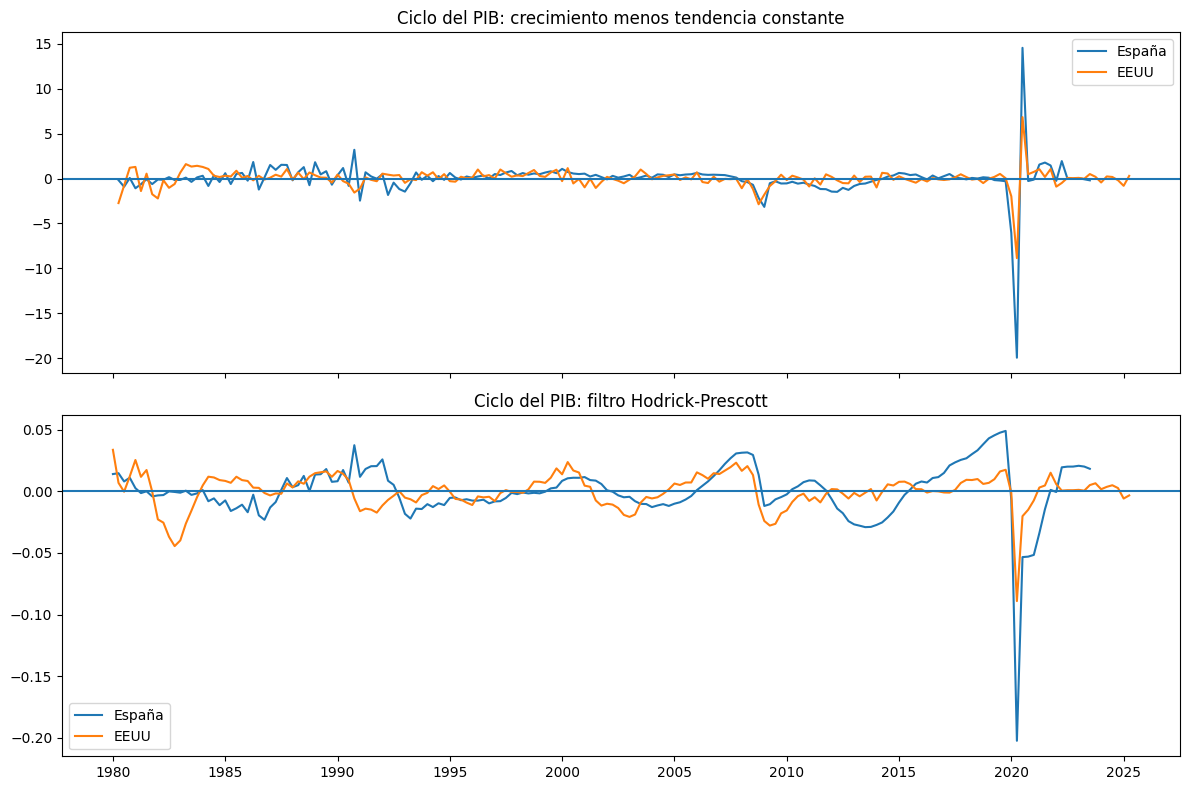

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Método crecimiento − media
axes[0].plot(cycles_esp[(gdp_esp_col, "growth_const")], label="España")
axes[0].plot(cycles_usa[(gdp_usa_col, "growth_const")], label="EEUU")
axes[0].axhline(0)
axes[0].set_title("Ciclo del PIB: crecimiento menos tendencia constante")
axes[0].legend()

# Método HP
axes[1].plot(cycles_esp[(gdp_esp_col, "hp_log")], label="España")
axes[1].plot(cycles_usa[(gdp_usa_col, "hp_log")], label="EEUU")
axes[1].axhline(0)
axes[1].set_title("Ciclo del PIB: filtro Hodrick-Prescott")
axes[1].legend()

plt.tight_layout()
plt.show()


<div style="background-color:#e6ffe6; padding:15px; border-radius:10px; border:1px solid #b3ffb3;">
El gráfico compara el ciclo del PIB de España y Estados Unidos obtenido mediante dos métodos distintos. En el panel superior se muestra el ciclo definido como el crecimiento observado menos una tendencia constante, mientras que en el panel inferior se presenta el ciclo obtenido aplicando el filtro de Hodrick-Prescott a los logaritmos del PIB.

En ambos países, los dos métodos identifican los principales episodios del ciclo económico. Destacan la recesión asociada a la crisis financiera de 2008–2009 y, de forma especialmente intensa, la caída de la actividad en 2020. En el caso de España, estas perturbaciones aparecen con mayor amplitud que en Estados Unidos, lo que refleja una mayor volatilidad de su ciclo económico.

El método basado en tasas de crecimiento genera fluctuaciones mucho más abruptas, con picos muy pronunciados, especialmente durante la pandemia, donde se observan caídas y rebotes extremos. Por el contrario, el ciclo obtenido con el filtro HP es más suave y persistente, ya que elimina parte del ruido de corto plazo y captura mejor las desviaciones prolongadas respecto a la tendencia.

En el panel inferior se aprecia que el ciclo HP de España presenta oscilaciones de mayor magnitud que el de Estados Unidos, confirmando que la economía española es más sensible a los shocks macroeconómicos. Estados Unidos muestra un ciclo más estable y de menor amplitud en ambos métodos.

En conjunto, ambos enfoques ofrecen información complementaria: el ciclo basado en el crecimiento es más adecuado para captar shocks bruscos de corto plazo, mientras que el filtro Hodrick-Prescott proporciona una visión más estructural y suave del ciclo económico.
</div>

> ## Prociclicidad y desfases temporales
> 
> Usando la definición de ciclo del apartado 1.1 (crecimiento observado menos una tendencia constante),
> se analiza si las siguientes variables son procíclicas, contracíclicas o acíclicas, y si presentan
> un comportamiento adelantado, coincidente o retrasado respecto al ciclo del PIB:
> 
> - Tasa de paro  
> - Horas trabajadas  
> - Consumo privado  
> - Consumo público  
> - Inversión  
> 
> El análisis se realiza mediante correlaciones cruzadas entre el ciclo de cada variable y el ciclo
> del PIB para distintos leads y lags.


In [37]:
def cross_corr(x, y, max_lag=8):
    """
    Correlación cruzada entre x (variable) e y (PIB)
    Devuelve correlaciones para lags [-max_lag, ..., 0, ..., +max_lag]
    """
    out = {}
    for k in range(-max_lag, max_lag + 1):
        out[k] = x.corr(y.shift(k))
    return pd.Series(out)

import numpy as np

def cycle_growth_const(series):
    g = 100 * np.log(series).diff()
    return g - g.mean()



In [38]:
# Ciclo del PIB
cycle_gdp = cycle_growth_const(df_esp["PIB_real"])

variables = {
    "Paro": df_esp["Paro"],
    "Horas trabajadas": df_esp["Horas"],
    "Consumo privado": df_esp["Consumo"],
    "Consumo público": df_esp["Gasto_publico"],
    "Inversión": df_esp["Inversion"]
}

results = {}

for name, series in variables.items():
    cycle_var = cycle_growth_const(series) 
    results[name] = cross_corr(cycle_var, cycle_gdp, max_lag=8)

corr_table = pd.DataFrame(results)
corr_table



,Paro,Horas trabajadas,Consumo privado,Consumo público,Inversión
-8,-0.021789,-0.046906,-0.037018,0.002968,-0.044516
-7,-0.008664,0.040879,0.070187,0.038940,0.088328
-6,-0.051597,-0.011760,-0.030683,-0.003031,0.069596
-5,-0.077834,-0.008853,-0.001386,0.050559,0.031724
-4,-0.072621,0.041350,0.114141,0.009132,0.076748
-3,-0.176881,0.084020,0.010534,0.032935,0.097052
-2,-0.118683,-0.019452,-0.038742,0.143962,0.101145
-1,-0.113582,-0.184686,-0.178646,0.064041,-0.116829
0,-0.293321,0.858637,0.941752,0.145696,0.810270
1,-0.323010,-0.211343,-0.189769,0.040579,-0.090120


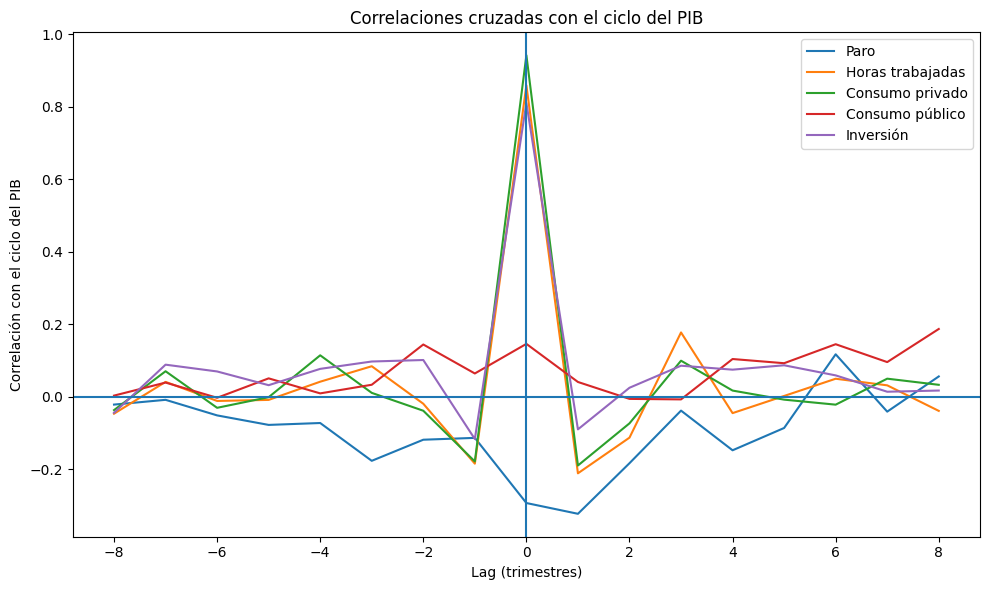

In [39]:
plt.figure(figsize=(10,6))

for col in corr_table.columns:
    plt.plot(corr_table.index, corr_table[col], label=col)

plt.axhline(0)
plt.axvline(0)
plt.xlabel("Lag (trimestres)")
plt.ylabel("Correlación con el ciclo del PIB")
plt.title("Correlaciones cruzadas con el ciclo del PIB")
plt.legend()
plt.tight_layout()
plt.show()


<div style="background-color:#e6ffe6; padding:15px; border-radius:10px; border:1px solid #414d7046;">
El gráfico muestra las correlaciones cruzadas entre el ciclo del PIB y el ciclo de distintas variables para distintos adelantos y retrasos. En general, la mayor parte de las variables alcanzan su máxima correlación en torno al retardo cero, lo que indica que su comportamiento está muy ligado al ciclo contemporáneo del PIB.

El consumo privado es claramente procíclico, con una correlación muy elevada y positiva en el periodo contemporáneo. Esto indica que el consumo se mueve prácticamente al mismo tiempo que el ciclo económico, sin adelantos ni retrasos relevantes.

Las horas trabajadas también son procíclicas, aunque con una correlación algo menor que la del consumo privado. Su máximo se produce cerca del retardo cero, lo que sugiere que el mercado laboral ajusta de forma bastante coincidente con el ciclo, sin un patrón claro de anticipación.

La inversión es procíclica, con una correlación alta en torno al periodo contemporáneo. Además, se aprecia cierta volatilidad en los retardos más alejados, lo que es coherente con la naturaleza más variable de la inversión, aunque el comovimiento principal con el PIB se concentra en torno a (0).

El consumo público muestra una correlación positiva pero claramente más débil que el resto de variables. Esto sugiere un comportamiento más acíclico o débilmente procíclico, consistente con el hecho de que el gasto público no responde de manera inmediata al ciclo económico.

La tasa de paro presenta un comportamiento claramente contracíclico. La correlación con el ciclo del PIB es negativa y alcanza su mayor magnitud en retardos positivos (en torno a (+1) trimestre), lo que indica que el paro reacciona con retraso a las fluctuaciones económicas. Esto refleja que los ajustes en el empleo suelen producirse después de los cambios en la actividad.

En conjunto, los resultados son coherentes con la evidencia macroeconómica habitual: consumo privado, horas trabajadas e inversión son procíclicos y mayoritariamente coincidentes, el consumo público es débilmente procíclico o acíclico, y el paro es contracíclico y retrasado respecto al ciclo del PIB.
</div>



> ## 1.4. Tratamiento del periodo post-Covid
> 
> El periodo posterior al Covid constituye un shock excepcional, caracterizado por caídas y rebotes muy intensos que no responden a la dinámica cíclica habitual de la economía. Por este motivo, resulta aconsejable tratar este episodio de manera específica para evitar que distorsione el análisis del ciclo económico.
> 
> Una primera propuesta consiste en excluir el periodo 2020–2021 de la muestra al estimar tendencias, correlaciones y volatilidades, manteniéndolo únicamente como un episodio excepcional de carácter descriptivo. De este modo, el análisis refleja mejor el comportamiento cíclico normal de la economía.
> 
> Una segunda opción es analizar el periodo post-Covid como un subperiodo independiente, comparando las propiedades del ciclo antes y después de 2020. Esto permite evaluar si se han producido cambios estructurales en la volatilidad o en la relación entre las principales variables macroeconómicas.
> 
> Finalmente, también puede optarse por emplear métodos de filtrado más robustos o menos sensibles a observaciones extremas, lo que reduce la influencia de shocks transitorios de gran magnitud como el asociado a la pandemia.
> 
> En conjunto, estas estrategias permiten aislar el carácter extraordinario del shock del Covid y obtener conclusiones más fiables sobre la dinámica cíclica subyacente de la economía.


